## Install and import dependencies

In [17]:
import copy
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from PIL import Image, ImageOps

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

PyTorch: 2.15.0+cpu
Device: cpu


## Load and explore the sklearn digits dataset

In [18]:
digits = load_digits()
X_raw = digits.images.astype(np.float32)  # [n_samples, 8, 8], values 0..16
y = digits.target.astype(np.int64)

print("Images:", X_raw.shape)
print("Labels:", y.shape)
print("Pixel min/max:", X_raw.min(), X_raw.max())
print("Classes:", np.unique(y))

Images: (1797, 8, 8)
Labels: (1797,)
Pixel min/max: 0.0 16.0
Classes: [0 1 2 3 4 5 6 7 8 9]


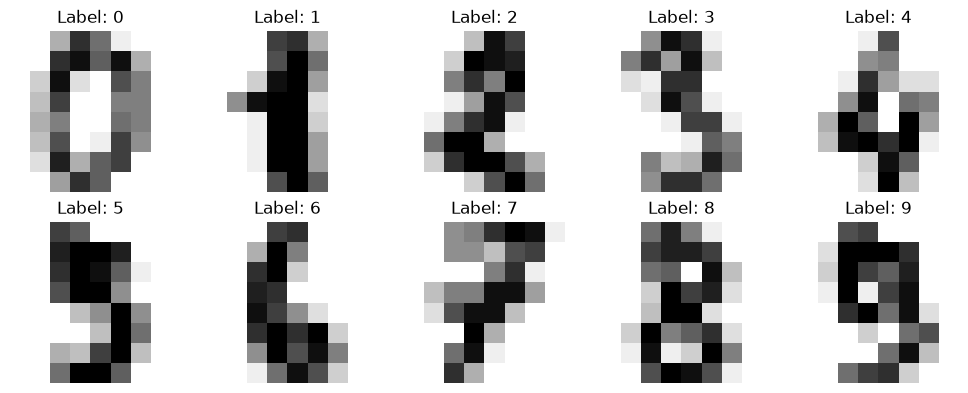

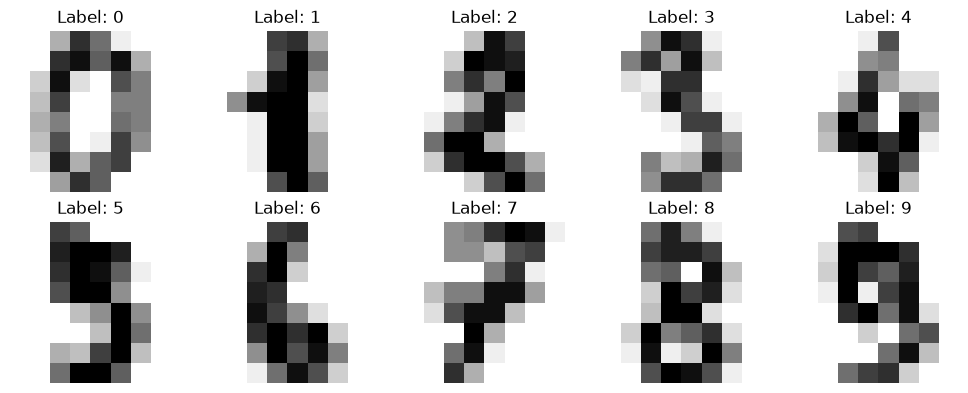

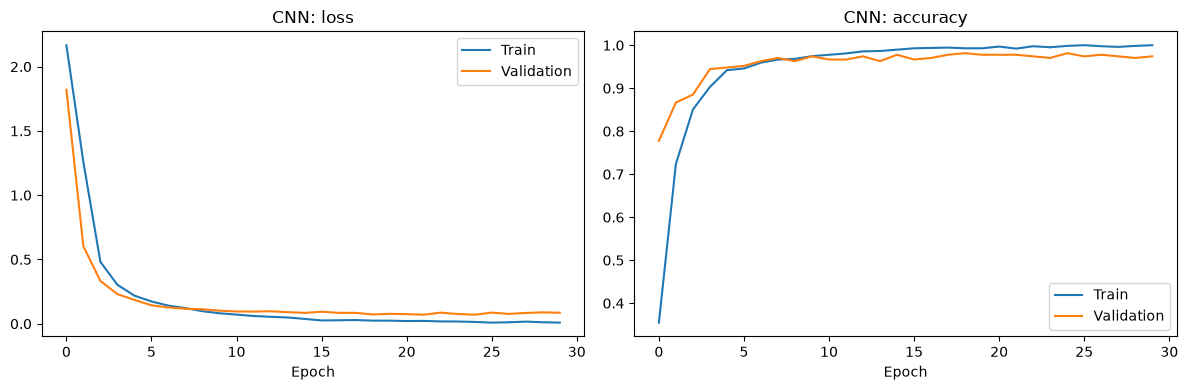

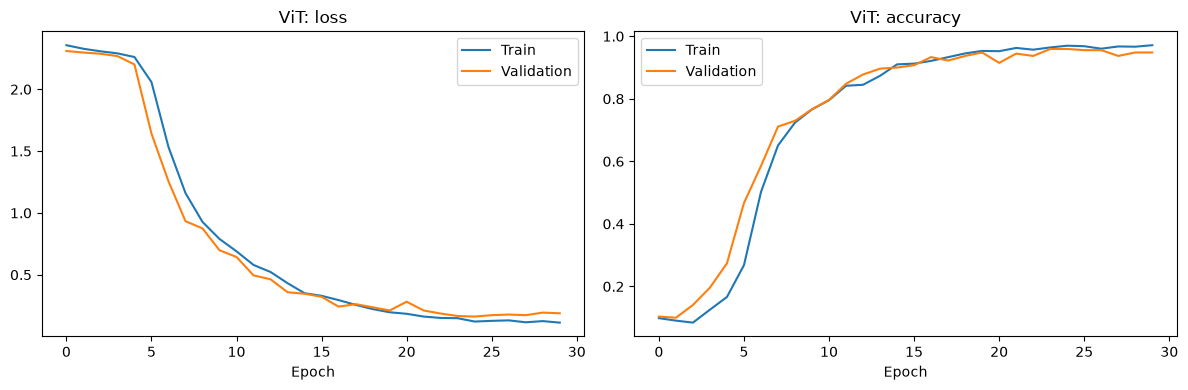

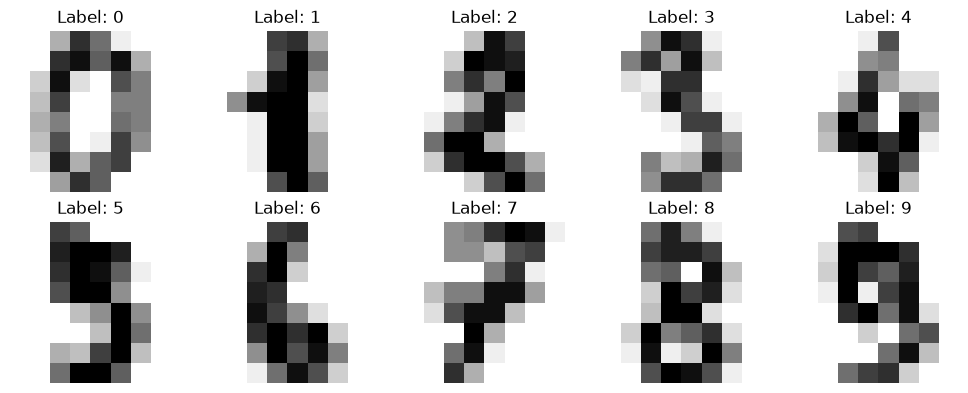

In [19]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for digit, ax in enumerate(axes.ravel()):
    idx = np.where(y == digit)[0][0]
    ax.imshow(X_raw[idx], cmap="gray_r", vmin=0, vmax=16)
    ax.set_title(f"Label: {y[idx]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Scale pixels and create one shared stratified split

In [20]:
# Match the training scale specified in the project guide: 0..16 -> 0..1
X = X_raw / 16.0

all_indices = np.arange(len(y))
train_idx, temp_idx = train_test_split(
    all_indices,
    test_size=0.30,
    random_state=SEED,
    stratify=y,
)
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=SEED,
    stratify=y[temp_idx],
)

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

print(f"Train: {len(train_idx)} ({len(train_idx)/len(y):.1%})")
print(f"Validation: {len(val_idx)} ({len(val_idx)/len(y):.1%})")
print(f"Test: {len(test_idx)} ({len(test_idx)/len(y):.1%})")
print("Scaled pixel range:", X.min(), X.max())

Train: 1257 (69.9%)
Validation: 270 (15.0%)
Test: 270 (15.0%)
Scaled pixel range: 0.0 1.0


In [21]:
# Verify each split contains all ten classes.
for name, labels in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(name, np.unique(labels, return_counts=True))

train (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([124, 127, 124, 128, 127, 127, 127, 125, 122, 126]))
validation (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([27, 27, 27, 27, 27, 28, 27, 27, 26, 27]))
test (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([27, 28, 26, 28, 27, 27, 27, 27, 26, 27]))


## Create PyTorch datasets and data loaders

In [22]:
def make_loader(images, labels, batch_size=64, shuffle=False):
    image_tensor = torch.tensor(images, dtype=torch.float32).unsqueeze(1)
    label_tensor = torch.tensor(labels, dtype=torch.long)
    dataset = TensorDataset(image_tensor, label_tensor)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)

BATCH_SIZE = 64
train_loader = make_loader(X_train, y_train, BATCH_SIZE, shuffle=True)
val_loader = make_loader(X_val, y_val, BATCH_SIZE)
test_loader = make_loader(X_test, y_test, BATCH_SIZE)

xb, yb = next(iter(train_loader))
print("CNN image batch:", xb.shape)  # [batch, 1, 8, 8]
print("Label batch:", yb.shape)

CNN image batch: torch.Size([64, 1, 8, 8])
Label batch: torch.Size([64])


In [23]:
# Model A — Convolutional Neural Network (CNN)
class SmallCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),  # 8x8 -> 4x4
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(p=0.30),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

cnn_model = SmallCNN().to(DEVICE)
print(cnn_model)
with torch.no_grad():
    sample_logits = cnn_model(xb[:4].to(DEVICE))
print("CNN output shape:", sample_logits.shape)  # [4, 10]

SmallCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1024, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
CNN output shape: torch.Size([4, 10])


In [24]:
# Model B — Small attention-based Vision Transformer (ViT)
class SmallViT(nn.Module):
    def __init__(
        self,
        image_size=8,
        patch_size=2,
        in_channels=1,
        embed_dim=64,
        num_heads=4,
        num_layers=2,
        mlp_dim=128,
        num_classes=10,
        dropout=0.10,
    ):
        super().__init__()
        assert image_size % patch_size == 0
        self.image_size = image_size
        self.patch_size = patch_size
        self.num_patches = (image_size // patch_size) ** 2
        patch_dim = in_channels * patch_size * patch_size

        self.patch_projection = nn.Linear(patch_dim, embed_dim)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.position_embedding = nn.Parameter(
            torch.zeros(1, self.num_patches + 1, embed_dim)
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=mlp_dim,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True,
        )
        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers,
        )
        self.norm = nn.LayerNorm(embed_dim)
        self.head = nn.Linear(embed_dim, num_classes)

        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.position_embedding, std=0.02)

    def make_patches(self, x):
        # x: [B, 1, 8, 8]
        # Result: [B, 16, 4] for 2x2 patches
        b = x.shape[0]
        p = self.patch_size
        patches = x.unfold(2, p, p).unfold(3, p, p)
        patches = patches.permute(0, 2, 3, 1, 4, 5).contiguous()
        return patches.view(b, self.num_patches, -1)

    def forward(self, x):
        patches = self.make_patches(x)
        tokens = self.patch_projection(patches)
        cls_tokens = self.cls_token.expand(x.shape[0], -1, -1)
        tokens = torch.cat([cls_tokens, tokens], dim=1)
        tokens = tokens + self.position_embedding
        tokens = self.transformer(tokens)
        cls_representation = self.norm(tokens[:, 0])
        return self.head(cls_representation)

vit_model = SmallViT().to(DEVICE)
print(vit_model)
with torch.no_grad():
    example_patches = vit_model.make_patches(xb[:4].to(DEVICE))
    vit_logits = vit_model(xb[:4].to(DEVICE))
print("Patch tensor shape:", example_patches.shape)  # [4, 16, 4]
print("ViT output shape:", vit_logits.shape)         # [4, 10]

SmallViT(
  (patch_projection): Linear(in_features=4, out_features=64, bias=True)
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=128, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=128, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
  (head): Linear(in_features=64, out_features=10, bias=True)
)
Patch tensor shape: torch.Size([4, 16, 4])
ViT output sh

C:\Users\786\AppData\Local\Temp\ipykernel_41588\2123433046.py:37: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


In [25]:
# Shared training and validation utilities
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss = 0.0
    all_true, all_pred = [], []

    for images, labels in loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * images.size(0)
        predictions = logits.argmax(dim=1)
        all_true.extend(labels.detach().cpu().numpy())
        all_pred.extend(predictions.detach().cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    accuracy = accuracy_score(all_true, all_pred)
    return avg_loss, accuracy

def train_model(model, train_loader, val_loader, epochs=30, learning_rate=1e-3):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    history = {
        "train_loss": [], "train_accuracy": [],
        "val_loss": [], "val_accuracy": [],
    }
    best_val_accuracy = -1.0
    best_state = copy.deepcopy(model.state_dict())

    for epoch in range(1, epochs + 1):
        train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc = run_epoch(model, val_loader, criterion)

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_acc)

        if val_acc > best_val_accuracy:
            best_val_accuracy = val_acc
            best_state = copy.deepcopy(model.state_dict())

        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"train loss {train_loss:.4f}, acc {train_acc:.4f} | "
            f"val loss {val_loss:.4f}, acc {val_acc:.4f}"
        )

    model.load_state_dict(best_state)
    return model, history

In [26]:
# Train the CNN
EPOCHS = 30

cnn_model, cnn_history = train_model(
    cnn_model,
    train_loader,
    val_loader,
    epochs=EPOCHS,
    learning_rate=1e-3,
)

Epoch 01/30 | train loss 2.1666, acc 0.3548 | val loss 1.8206, acc 0.7778
Epoch 02/30 | train loss 1.2562, acc 0.7239 | val loss 0.6020, acc 0.8667
Epoch 03/30 | train loss 0.4807, acc 0.8504 | val loss 0.3325, acc 0.8852
Epoch 04/30 | train loss 0.3027, acc 0.9029 | val loss 0.2300, acc 0.9444
Epoch 05/30 | train loss 0.2184, acc 0.9419 | val loss 0.1853, acc 0.9481
Epoch 06/30 | train loss 0.1735, acc 0.9459 | val loss 0.1436, acc 0.9519
Epoch 07/30 | train loss 0.1406, acc 0.9594 | val loss 0.1263, acc 0.9630
Epoch 08/30 | train loss 0.1212, acc 0.9666 | val loss 0.1163, acc 0.9704
Epoch 09/30 | train loss 0.0974, acc 0.9682 | val loss 0.1129, acc 0.9630
Epoch 10/30 | train loss 0.0814, acc 0.9745 | val loss 0.1016, acc 0.9741
Epoch 11/30 | train loss 0.0711, acc 0.9777 | val loss 0.0953, acc 0.9667
Epoch 12/30 | train loss 0.0603, acc 0.9809 | val loss 0.0945, acc 0.9667
Epoch 13/30 | train loss 0.0540, acc 0.9857 | val loss 0.0969, acc 0.9741
Epoch 14/30 | train loss 0.0486, acc 0

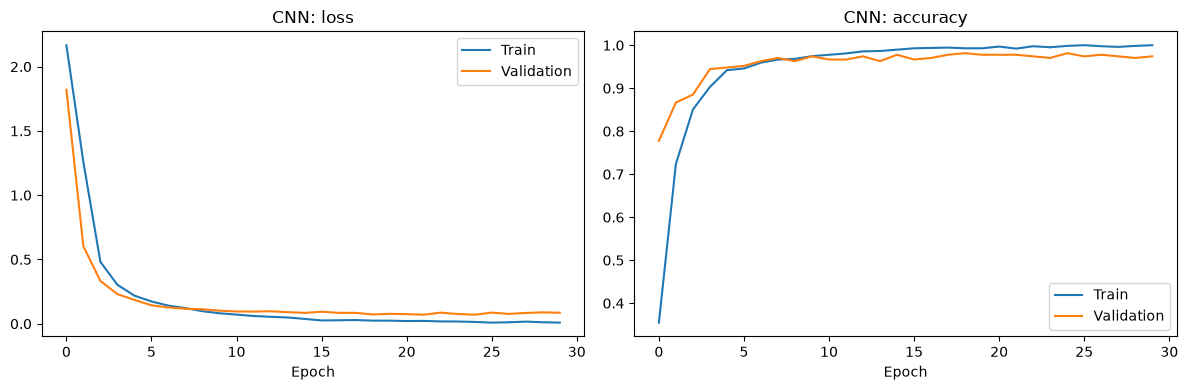

In [27]:
def plot_history(history, model_name):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history["train_loss"], label="Train")
    axes[0].plot(history["val_loss"], label="Validation")
    axes[0].set_title(f"{model_name}: loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    axes[1].plot(history["train_accuracy"], label="Train")
    axes[1].plot(history["val_accuracy"], label="Validation")
    axes[1].set_title(f"{model_name}: accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

plot_history(cnn_history, "CNN")

Epoch 01/30 | train loss 2.3563, acc 0.0986 | val loss 2.3093, acc 0.1037
Epoch 02/30 | train loss 2.3276, acc 0.0907 | val loss 2.2971, acc 0.1000
Epoch 03/30 | train loss 2.3071, acc 0.0843 | val loss 2.2872, acc 0.1407
Epoch 04/30 | train loss 2.2903, acc 0.1257 | val loss 2.2682, acc 0.1963
Epoch 05/30 | train loss 2.2607, acc 0.1663 | val loss 2.2006, acc 0.2741
Epoch 06/30 | train loss 2.0578, acc 0.2681 | val loss 1.6414, acc 0.4667
Epoch 07/30 | train loss 1.5332, acc 0.5020 | val loss 1.2562, acc 0.5852
Epoch 08/30 | train loss 1.1606, acc 0.6508 | val loss 0.9330, acc 0.7111
Epoch 09/30 | train loss 0.9272, acc 0.7239 | val loss 0.8748, acc 0.7296
Epoch 10/30 | train loss 0.7893, acc 0.7661 | val loss 0.6980, acc 0.7667
Epoch 11/30 | train loss 0.6893, acc 0.7955 | val loss 0.6438, acc 0.7963
Epoch 12/30 | train loss 0.5792, acc 0.8417 | val loss 0.4948, acc 0.8481
Epoch 13/30 | train loss 0.5223, acc 0.8449 | val loss 0.4634, acc 0.8778
Epoch 14/30 | train loss 0.4318, acc 0

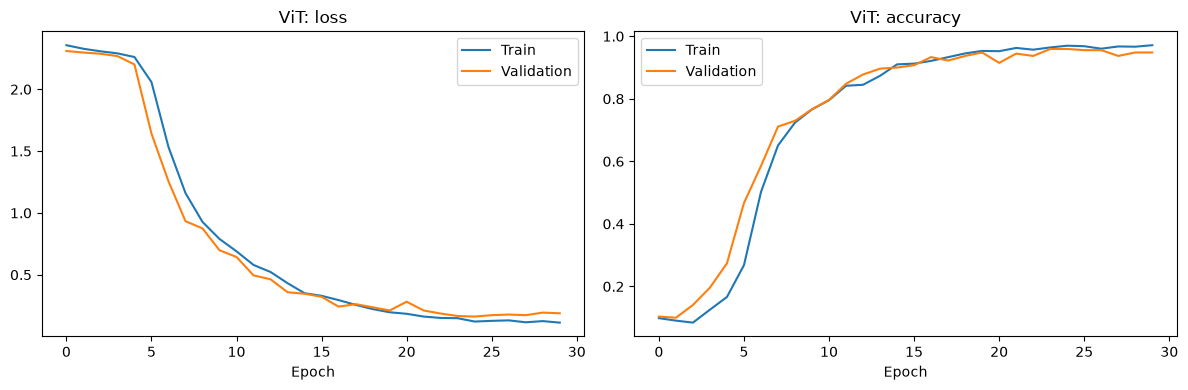

In [28]:
# Train the Vision Transformer
vit_model, vit_history = train_model(
    vit_model,
    train_loader,
    val_loader,
    epochs=EPOCHS,
    learning_rate=5e-4,
)
plot_history(vit_history, "ViT")

In [16]:
# Majority-class baseline
majority_class = int(np.bincount(y_train).argmax())
baseline_predictions = np.full_like(y_test, fill_value=majority_class)

baseline_accuracy = accuracy_score(y_test, baseline_predictions)
baseline_macro_f1 = f1_score(y_test, baseline_predictions, average="macro", zero_division=0)

print("Majority class from training data:", majority_class)
print(f"Baseline test accuracy: {baseline_accuracy:.4f}")
print(f"Baseline test macro F1: {baseline_macro_f1:.4f}")

Majority class from training data: 3
Baseline test accuracy: 0.1037
Baseline test macro F1: 0.0188


In [29]:
# Final test evaluation
@torch.no_grad()
def get_predictions(model, loader):
    model.eval()
    y_true, y_pred = [], []
    for images, labels in loader:
        logits = model(images.to(DEVICE))
        y_pred.extend(logits.argmax(dim=1).cpu().numpy())
        y_true.extend(labels.numpy())
    return np.array(y_true), np.array(y_pred)

cnn_true, cnn_pred = get_predictions(cnn_model, test_loader)
vit_true, vit_pred = get_predictions(vit_model, test_loader)

results = {
    "Majority baseline": {
        "accuracy": accuracy_score(y_test, baseline_predictions),
        "macro_f1": f1_score(y_test, baseline_predictions, average="macro", zero_division=0),
    },
    "CNN": {
        "accuracy": accuracy_score(cnn_true, cnn_pred),
        "macro_f1": f1_score(cnn_true, cnn_pred, average="macro", zero_division=0),
    },
    "ViT": {
        "accuracy": accuracy_score(vit_true, vit_pred),
        "macro_f1": f1_score(vit_true, vit_pred, average="macro", zero_division=0),
    },
}

for model_name, metrics in results.items():
    print(
        f"{model_name:18s} | "
        f"test accuracy: {metrics['accuracy']:.4f} | "
        f"macro F1: {metrics['macro_f1']:.4f}"
    )

Majority baseline  | test accuracy: 0.1037 | macro F1: 0.0188
CNN                | test accuracy: 0.9889 | macro F1: 0.9887
ViT                | test accuracy: 0.9444 | macro F1: 0.9444


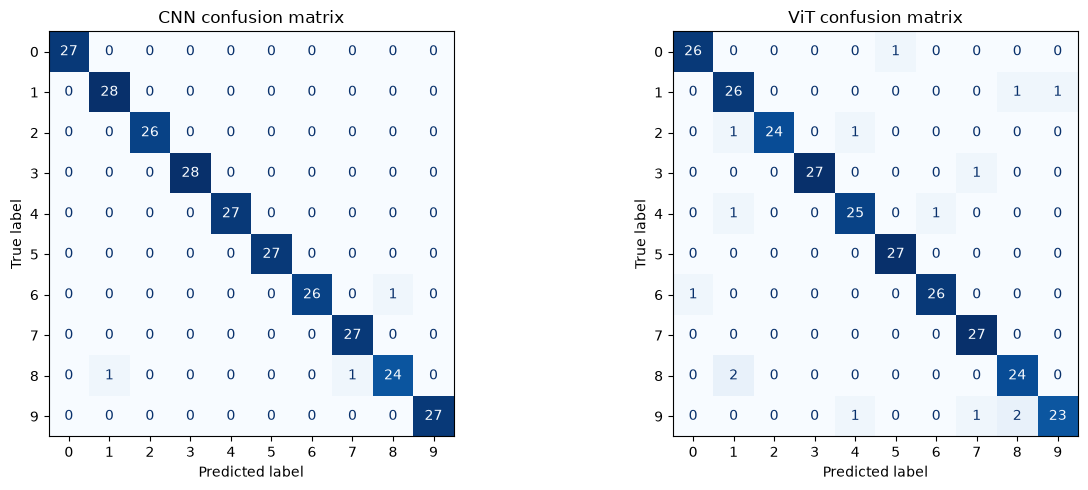

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, true, pred, name in [
    (axes[0], cnn_true, cnn_pred, "CNN"),
    (axes[1], vit_true, vit_pred, "ViT"),
]:
    cm = confusion_matrix(true, pred, labels=np.arange(10))
    ConfusionMatrixDisplay(cm, display_labels=np.arange(10)).plot(
        ax=ax, cmap="Blues", colorbar=False
    )
    ax.set_title(f"{name} confusion matrix")
plt.tight_layout()
plt.show()

In [31]:
print("CNN classification report")
print(classification_report(cnn_true, cnn_pred, digits=4, zero_division=0))
print("ViT classification report")
print(classification_report(vit_true, vit_pred, digits=4, zero_division=0))

CNN classification report
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        27
           1     0.9655    1.0000    0.9825        28
           2     1.0000    1.0000    1.0000        26
           3     1.0000    1.0000    1.0000        28
           4     1.0000    1.0000    1.0000        27
           5     1.0000    1.0000    1.0000        27
           6     1.0000    0.9630    0.9811        27
           7     0.9643    1.0000    0.9818        27
           8     0.9600    0.9231    0.9412        26
           9     1.0000    1.0000    1.0000        27

    accuracy                         0.9889       270
   macro avg     0.9890    0.9886    0.9887       270
weighted avg     0.9890    0.9889    0.9888       270

ViT classification report
              precision    recall  f1-score   support

           0     0.9630    0.9630    0.9630        27
           1     0.8667    0.9286    0.8966        28
           2     1.0000   

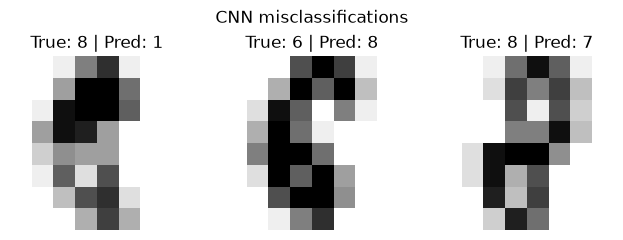

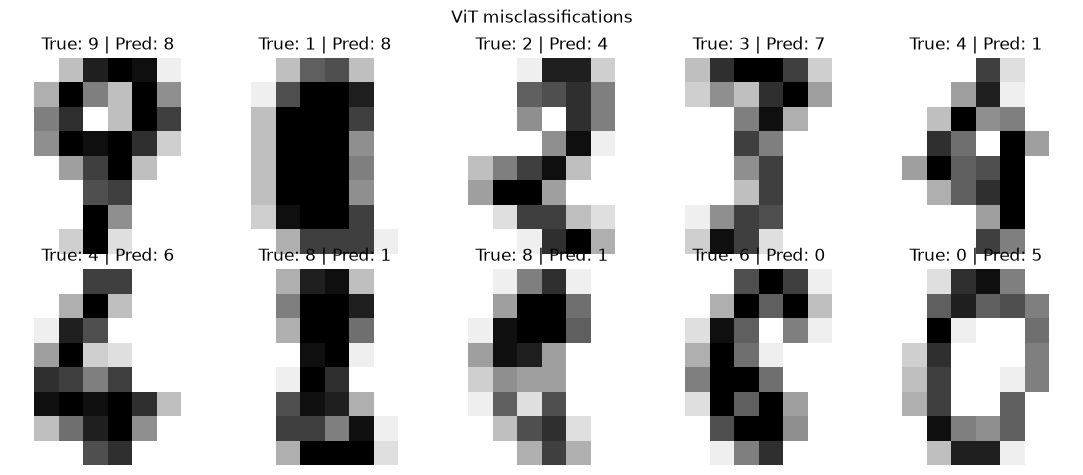

In [32]:
# Inspect misclassified examples
def show_errors(images, true_labels, predictions, title, max_items=10):
    error_indices = np.where(true_labels != predictions)[0][:max_items]
    if len(error_indices) == 0:
        print(f"{title}: no errors on this test split.")
        return

    cols = min(5, len(error_indices))
    rows = int(np.ceil(len(error_indices) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(2.2 * cols, 2.4 * rows))
    axes = np.array(axes).reshape(-1)

    for ax, idx in zip(axes, error_indices):
        ax.imshow(images[idx], cmap="gray_r", vmin=0, vmax=1)
        ax.set_title(f"True: {true_labels[idx]} | Pred: {predictions[idx]}")
        ax.axis("off")
    for ax in axes[len(error_indices):]:
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

show_errors(X_test, cnn_true, cnn_pred, "CNN misclassifications")
show_errors(X_test, vit_true, vit_pred, "ViT misclassifications")

In [ ]:
# Reusable uploaded-photo preprocessing (Pillow)
def prepare_uploaded_digit(image_or_path, threshold=20):
    # Accept a PIL image, file-like object, or filesystem path.
    image = Image.open(image_or_path) if not isinstance(image_or_path, Image.Image) else image_or_path
    gray = ImageOps.grayscale(image)

    # Normalize polarity: digit strokes should be bright, background dark.
    arr = np.asarray(gray, dtype=np.uint8)
    if arr.mean() > 127:
        gray = ImageOps.invert(gray)

    arr = np.asarray(gray, dtype=np.uint8)
    mask = arr > threshold
    if not mask.any():
        raise ValueError("The uploaded image appears blank. Please upload a clear image containing one digit.")

    ys, xs = np.where(mask)
    left, right = xs.min(), xs.max() + 1
    top, bottom = ys.min(), ys.max() + 1
    cropped = gray.crop((left, top, right, bottom))

    # Keep aspect ratio and leave a one-pixel margin around the digit.
    cropped.thumbnail((6, 6), Image.Resampling.LANCZOS)
    canvas = Image.new("L", (8, 8), color=0)
    paste_x = (8 - cropped.width) // 2
    paste_y = (8 - cropped.height) // 2
    canvas.paste(cropped, (paste_x, paste_y))

    prepared_uint8 = np.asarray(canvas, dtype=np.uint8)
    prepared_float = prepared_uint8.astype(np.float32) / 255.0
    return prepared_float, canvas

# Example using a synthetic image is optional; pass a path or uploaded file to the function.
# prepared_array, prepared_pil = prepare_uploaded_digit("models/my_digit.png")
# plt.figure(figsize=(3, 3))
# plt.imshow(prepared_pil.resize((240, 240), Image.Resampling.NEAREST), cmap="gray")
# plt.title("Prepared 8x8 digit")
# plt.axis("off")
# plt.show()

In [35]:
# Predict one prepared image with both models
@torch.no_grad()
def predict_both(prepared_8x8):
    image_tensor = torch.tensor(
        prepared_8x8, dtype=torch.float32
    ).unsqueeze(0).unsqueeze(0).to(DEVICE)  # [1, 1, 8, 8]

    cnn_model.eval()
    vit_model.eval()

    cnn_probs = torch.softmax(cnn_model(image_tensor), dim=1).squeeze(0).cpu().numpy()
    vit_probs = torch.softmax(vit_model(image_tensor), dim=1).squeeze(0).cpu().numpy()

    return {
        "cnn_digit": int(cnn_probs.argmax()),
        "cnn_probabilities": cnn_probs,
        "vit_digit": int(vit_probs.argmax()),
        "vit_probabilities": vit_probs,
    }

# Example:
# prepared_array, prepared_preview = prepare_uploaded_digit("my_digit.png")
# output = predict_both(prepared_array)
# print("CNN:", output["cnn_digit"])
# print("ViT:", output["vit_digit"])

In [ ]:
# Save model checkpoints and project settings
ARTIFACT_DIR = Path("artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

cnn_checkpoint = {
    "model_name": "SmallCNN",
    "model_state_dict": cnn_model.cpu().state_dict(),
    "num_classes": 10,
    "input_shape": [1, 8, 8],
    "pixel_scale": "divide_by_16_for_sklearn; divide_by_255_for_uploaded_8bit",
    "class_mapping": {i: str(i) for i in range(10)},
}
vit_checkpoint = {
    "model_name": "SmallViT",
    "model_state_dict": vit_model.cpu().state_dict(),
    "config": {
        "image_size": 8,
        "patch_size": 2,
        "embed_dim": 64,
        "num_heads": 4,
        "num_layers": 2,
        "mlp_dim": 128,
        "num_classes": 10,
        "dropout": 0.10,
    },
    "pixel_scale": "divide_by_16_for_sklearn; divide_by_255_for_uploaded_8bit",
    "class_mapping": {i: str(i) for i in range(10)},
}

torch.save(cnn_checkpoint, ARTIFACT_DIR / "models/cnn_model.pth")
torch.save(vit_checkpoint, ARTIFACT_DIR / "models/vit_model.pth")

print("Saved:")
print(ARTIFACT_DIR / "models/cnn_model.pth")
print(ARTIFACT_DIR / "models/vit_model.pth")

# Move models back to the selected device for continued notebook use.
cnn_model.to(DEVICE)
vit_model.to(DEVICE)

In [ ]:
# Verify that checkpoints reload correctly
# weights_only=False is used because this checkpoint contains ordinary Python metadata
# as well as the state dictionary. Only load checkpoints you created/trust.
cnn_loaded_ckpt = torch.load(ARTIFACT_DIR / "models/cnn_model.pth", map_location=DEVICE, weights_only=False)
vit_loaded_ckpt = torch.load(ARTIFACT_DIR / "models/vit_model.pth", map_location=DEVICE, weights_only=False)

cnn_reloaded = SmallCNN().to(DEVICE)
cnn_reloaded.load_state_dict(cnn_loaded_ckpt["model_state_dict"])
cnn_reloaded.eval()

vit_reloaded = SmallViT(**vit_loaded_ckpt["config"]).to(DEVICE)
vit_reloaded.load_state_dict(vit_loaded_ckpt["model_state_dict"])
vit_reloaded.eval()

with torch.no_grad():
    check_x = torch.tensor(X_test[:8], dtype=torch.float32).unsqueeze(1).to(DEVICE)
    original_cnn = cnn_model(check_x).argmax(1)
    reloaded_cnn = cnn_reloaded(check_x).argmax(1)
    original_vit = vit_model(check_x).argmax(1)
    reloaded_vit = vit_reloaded(check_x).argmax(1)

print("CNN reload matches:", torch.equal(original_cnn, reloaded_cnn))
print("ViT reload matches:", torch.equal(original_vit, reloaded_vit))